In [1]:
import pandas as pd
import numpy as np

# Load directly from your GitHub repo's raw CSV link
url = "https://raw.githubusercontent.com/DestinyAbuwa/Sleep-Debt-Prediction/main/data/raw/bedtime_screentime_sleep_debt.csv"
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\n--- Missing Values & Data Types ---")
print(df.info())
print("\n--- Duplicate Rows ---")
print("Duplicates:", df.duplicated().sum())
print("\n--- Target Variable Breakdown (sleep_debt_category) ---")
print(df['sleep_debt_category'].value_counts())
print("\n--- Continuous Target Summary (next_day_fatigue_score) ---")
print(df['next_day_fatigue_score'].describe())

Dataset Shape: (8500, 18)

--- Missing Values & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   str    
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   str    
 3   occupation_type           8500 non-null   str    
 4   chronotype                8500 non-null   str    
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   str    
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_

In [2]:
print(df['sleep_debt_category'].value_counts())
print("\nPercentages:")
print(df['sleep_debt_category'].value_counts(normalize=True) * 100)

sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Percentages:
sleep_debt_category
Moderate Debt        52.494118
Mild Deficit         23.576471
Optimal Recovery     16.317647
Severe Sleep Debt     7.611765
Name: proportion, dtype: float64


Class 0: 3,391 samples (39.89%)
Class 1: 5,109 samples (60.11%)


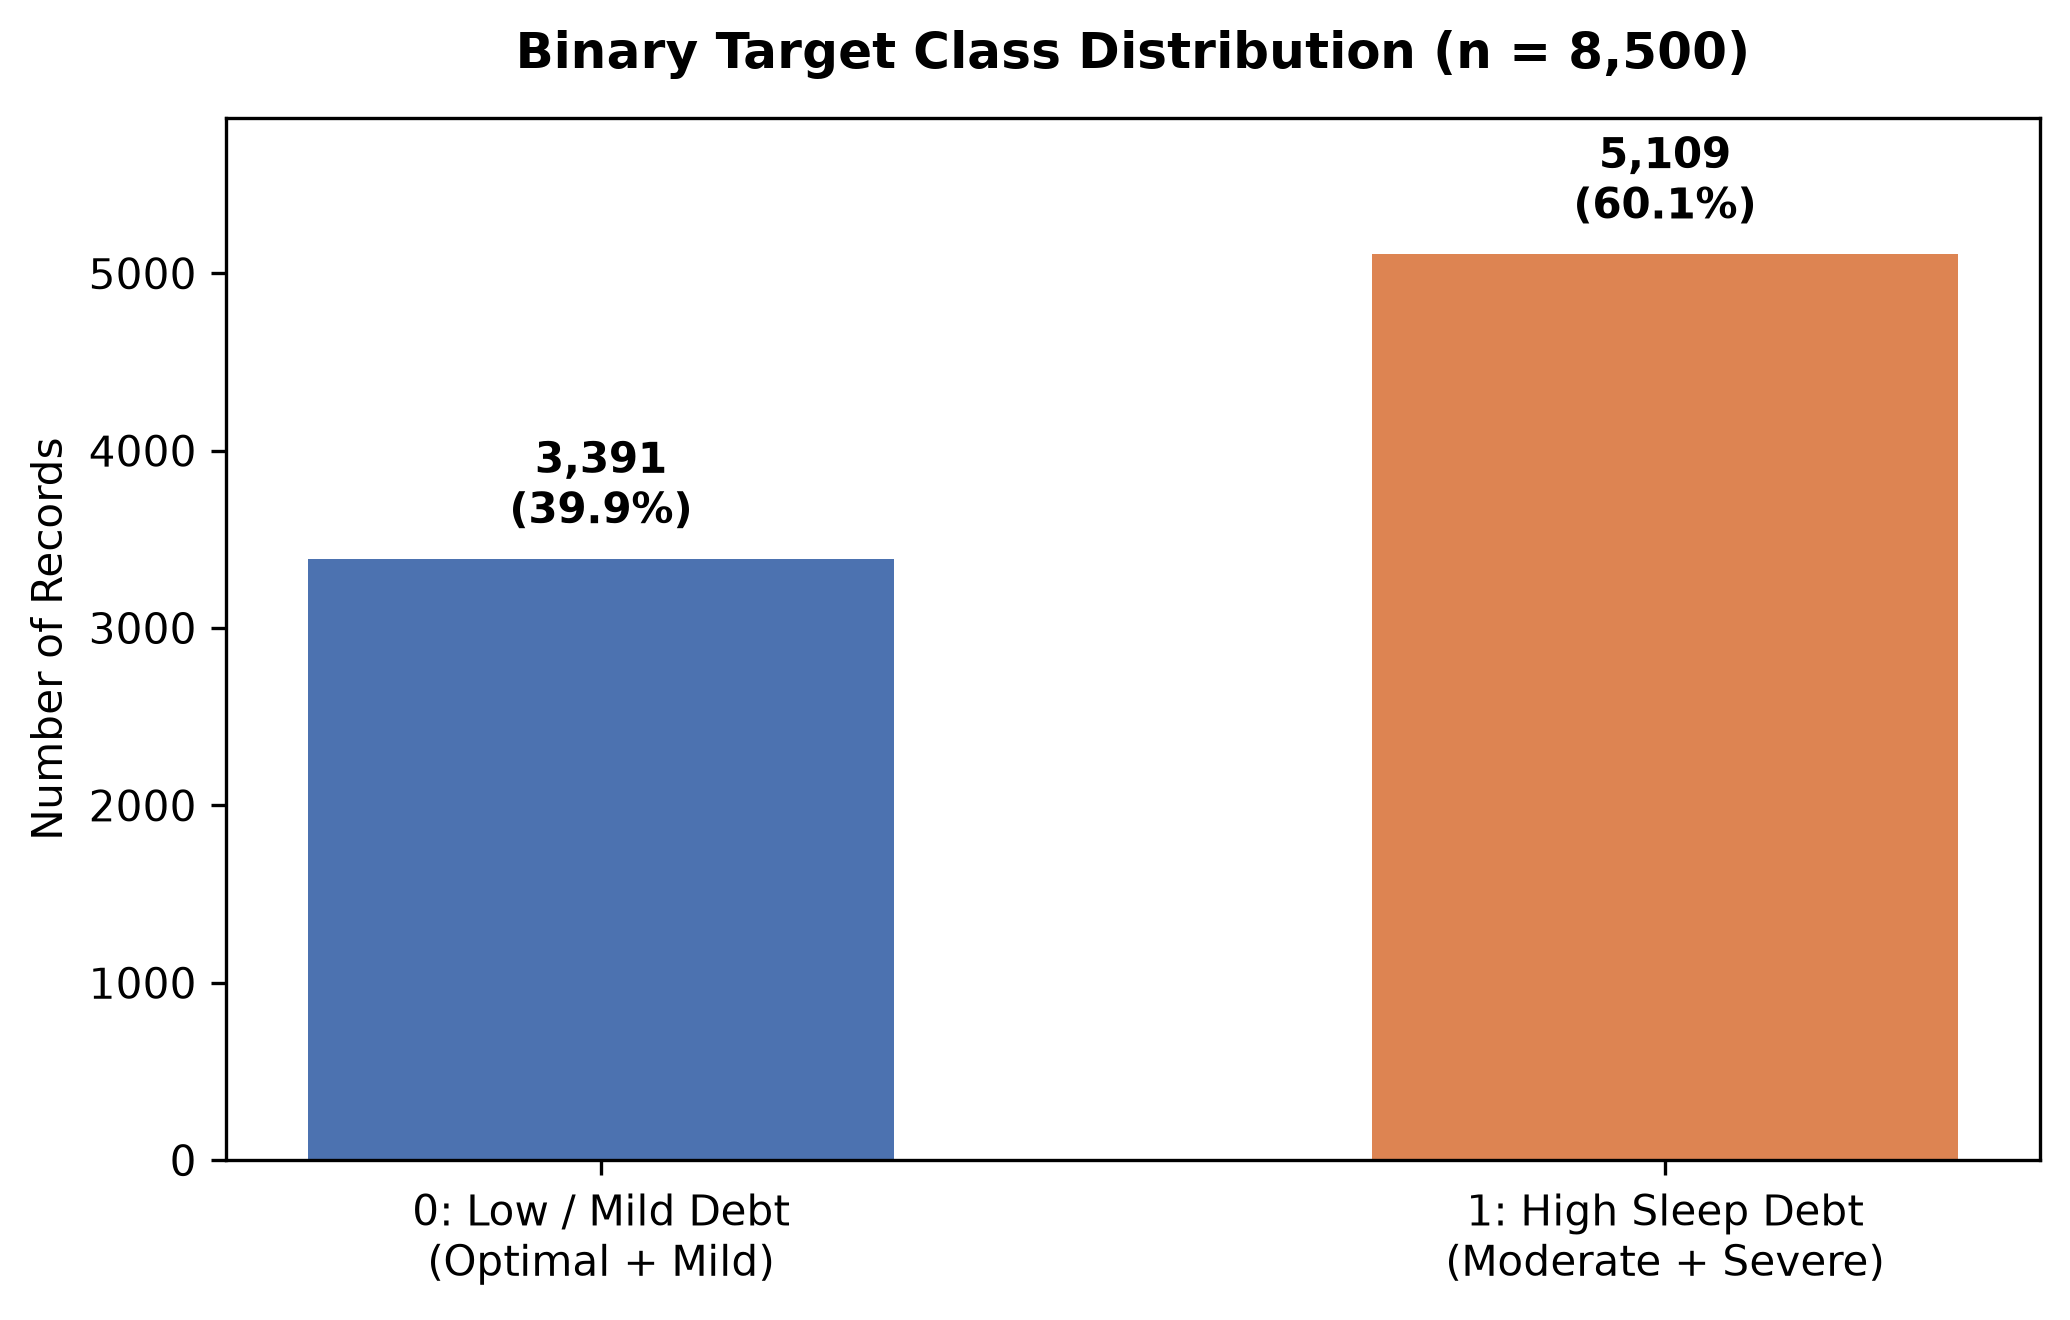

In [3]:
import matplotlib.pyplot as plt
import os

# Create folders locally in your notebook environment
os.makedirs("figures", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

# Map 4 categories into Binary Target (0 = Low/Mild Debt, 1 = Moderate/Severe Debt)
target_map = {
    'Optimal Recovery': 0,
    'Mild Deficit': 0,
    'Moderate Debt': 1,
    'Severe Sleep Debt': 1
}
df['high_sleep_debt'] = df['sleep_debt_category'].map(target_map)

# Verify counts and percentages
counts = df['high_sleep_debt'].value_counts().sort_index()
pcts = df['high_sleep_debt'].value_counts(normalize=True).sort_index() * 100
for cls in [0, 1]:
    print(f"Class {cls}: {counts[cls]:,} samples ({pcts[cls]:.2f}%)")

# Plot & save high-resolution bar chart for Section 3 of the report
plt.figure(figsize=(7, 4.5), dpi=300)
labels = ['0: Low / Mild Debt\n(Optimal + Mild)', '1: High Sleep Debt\n(Moderate + Severe)']
bars = plt.bar(labels, counts.values, color=['#4C72B0', '#DD8452'], width=0.55)

plt.title('Binary Target Class Distribution (n = 8,500)', fontsize=12, fontweight='bold', pad=12)
plt.ylabel('Number of Records', fontsize=10)
plt.ylim(0, max(counts.values) * 1.15)

for bar, pct in zip(bars, pcts.values):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 120, f'{yval:,}\n({pct:.1f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/class_distribution.png', dpi=300)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

# 1. Drop identifier and target/leaky columns
drop_cols = ['user_id', 'sleep_debt_category', 'next_day_fatigue_score']
X = df.drop(columns=drop_cols + ['high_sleep_debt'])
y = df['high_sleep_debt']

# 2. One-hot encode categorical columns
cat_cols = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print("Total features after encoding:", X_encoded.shape[1])
print("Feature list:", list(X_encoded.columns))

# 3. Stratified 80/20 Train/Test Split (random_state=42 for team reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")

# 4. Save processed train & test sets (including target column)
train_df = X_train.copy()
train_df['high_sleep_debt'] = y_train
test_df = X_test.copy()
test_df['high_sleep_debt'] = y_test

train_df.to_csv('data/processed/train_full.csv', index=False)
test_df.to_csv('data/processed/test_full.csv', index=False)

# Also save pre-sleep-habits-only versions for Research Question 5
overnight_cols = ['sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct']
train_df.drop(columns=overnight_cols).to_csv('data/processed/train_behavioral_only.csv', index=False)
test_df.drop(columns=overnight_cols).to_csv('data/processed/test_behavioral_only.csv', index=False)

print("Saved all processed datasets and figures/class_distribution.png!")

Total features after encoding: 24
Feature list: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'gender_Male', 'gender_Non-Binary', 'occupation_type_Freelance / Creative', 'occupation_type_Healthcare / Shift Worker', 'occupation_type_Remote Tech', 'occupation_type_Student', 'chronotype_Morning Lark', 'chronotype_Night Owl', 'primary_bedtime_app_Messaging / Chat', 'primary_bedtime_app_News / Reading', 'primary_bedtime_app_Streaming (Netflix/Hulu)', 'primary_bedtime_app_TikTok / Reels', 'primary_bedtime_app_YouTube']

Train shape: (6800, 24), Test shape: (1700, 24)
Saved all processed datasets and figures/class_distribution.png!
